# Data

In [5]:
import datetime as dt
import pandas as pd
from EDA import *


CHANNELS = [
    "temperature_2m",
    "shortwave_radiation",
    "direct_radiation",
    "cloud_cover_low",
    "cloud_cover_mid",
    "cloud_cover_high",
    "cloud_cover",
    "is_day"
]

START_DATE = dt.datetime(2025, 10, 15, 0, 0)
END_DATE = dt.datetime(2026, 9, 15, 23, 0)

PV_CSV = '../Datasets/PV/PV_DTU.csv'
NWP_CSV = '../Datasets/NWP/ECMWF_forecast_DTU.csv'

# Load Datasets
nwp = pd.read_csv(NWP_CSV, parse_dates=["init_time_utc"])
pv = pd.read_csv(PV_CSV, parse_dates=["time"])

step = pd.to_timedelta(nwp["step"], unit="h")
nwp['time'] = (nwp['init_time_utc'] + step).dt.floor("h")
df = pd.merge(pv, nwp, how="outer")

df = df.set_index("time").sort_index()

Correlation between the different input variables

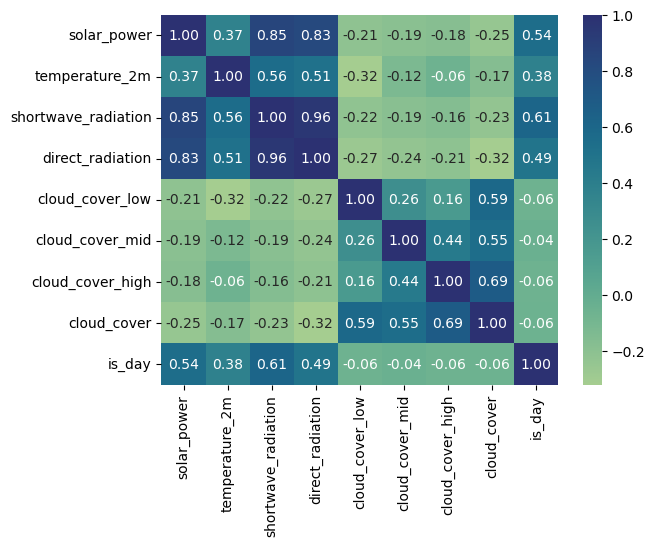

In [2]:
correlation_dataset = df.drop(columns = ['latitude', 'longitude', 'init_time_utc', 'step'])
correlation_heatmap(correlation_dataset)

Plot metrics against solar power output

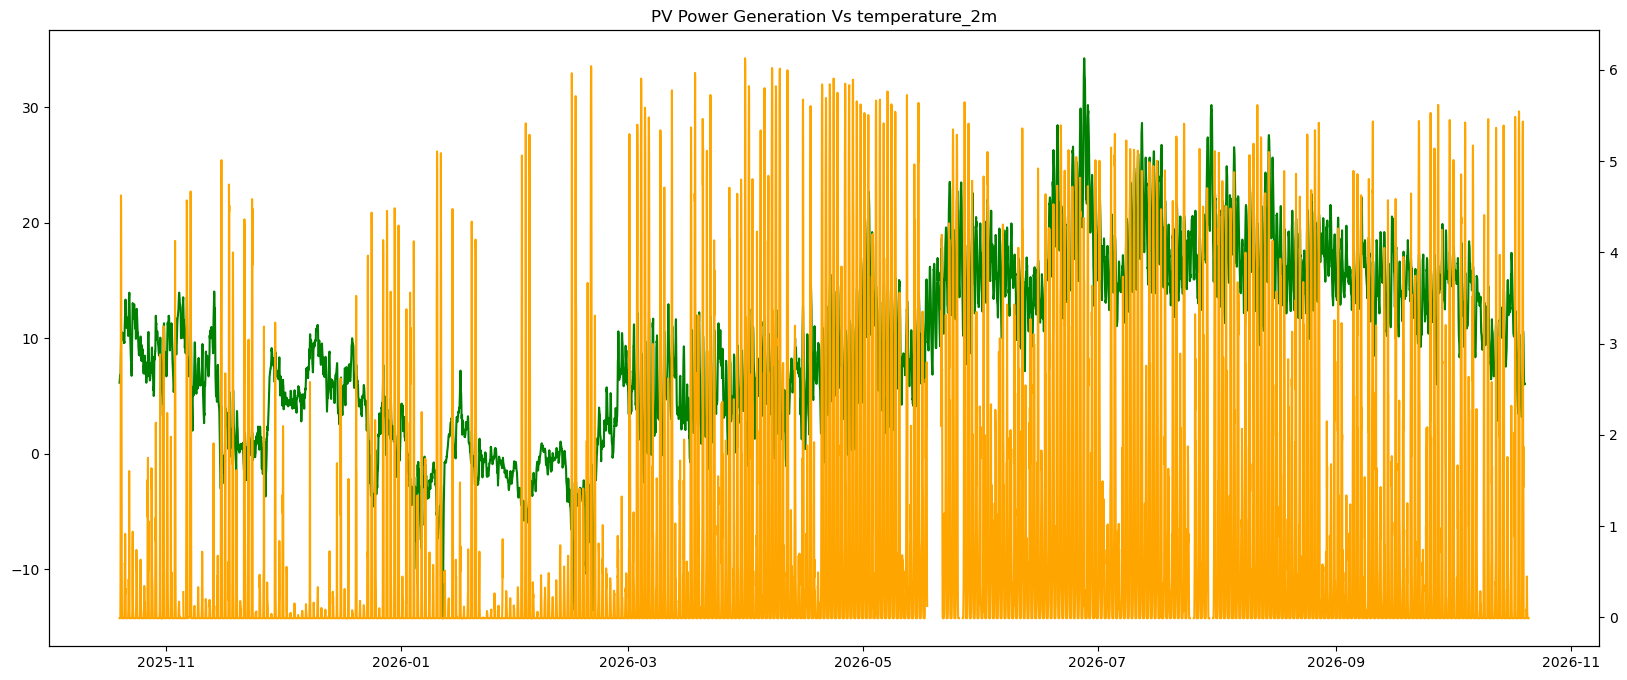

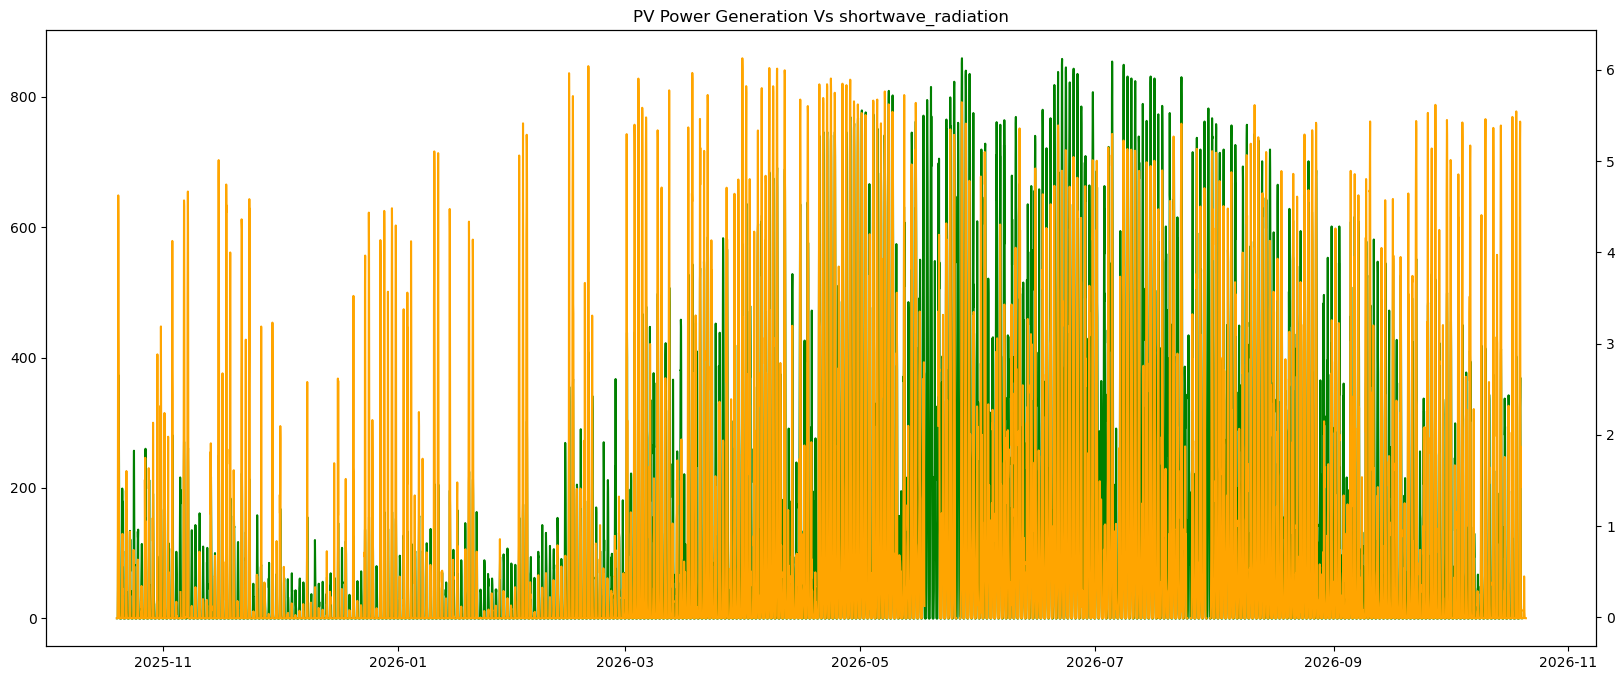

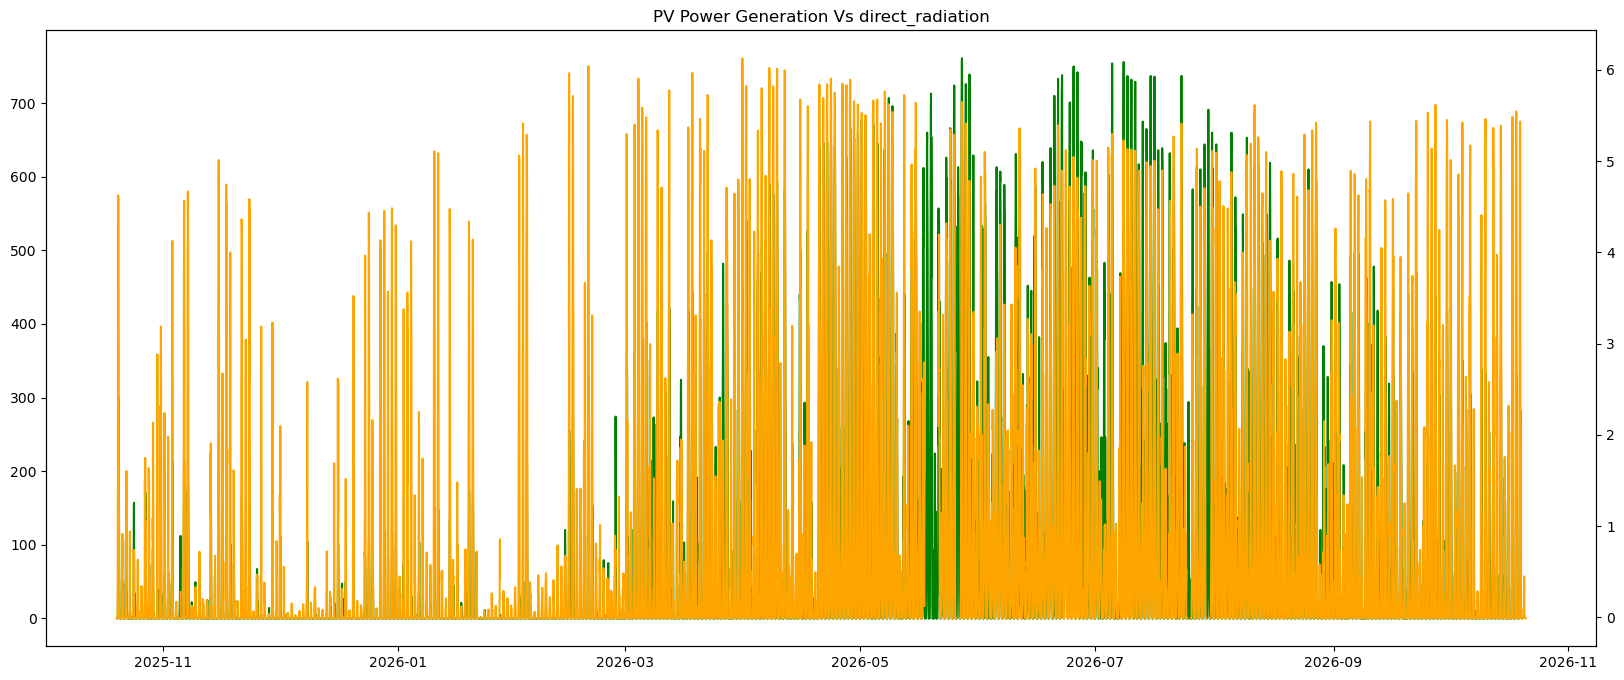

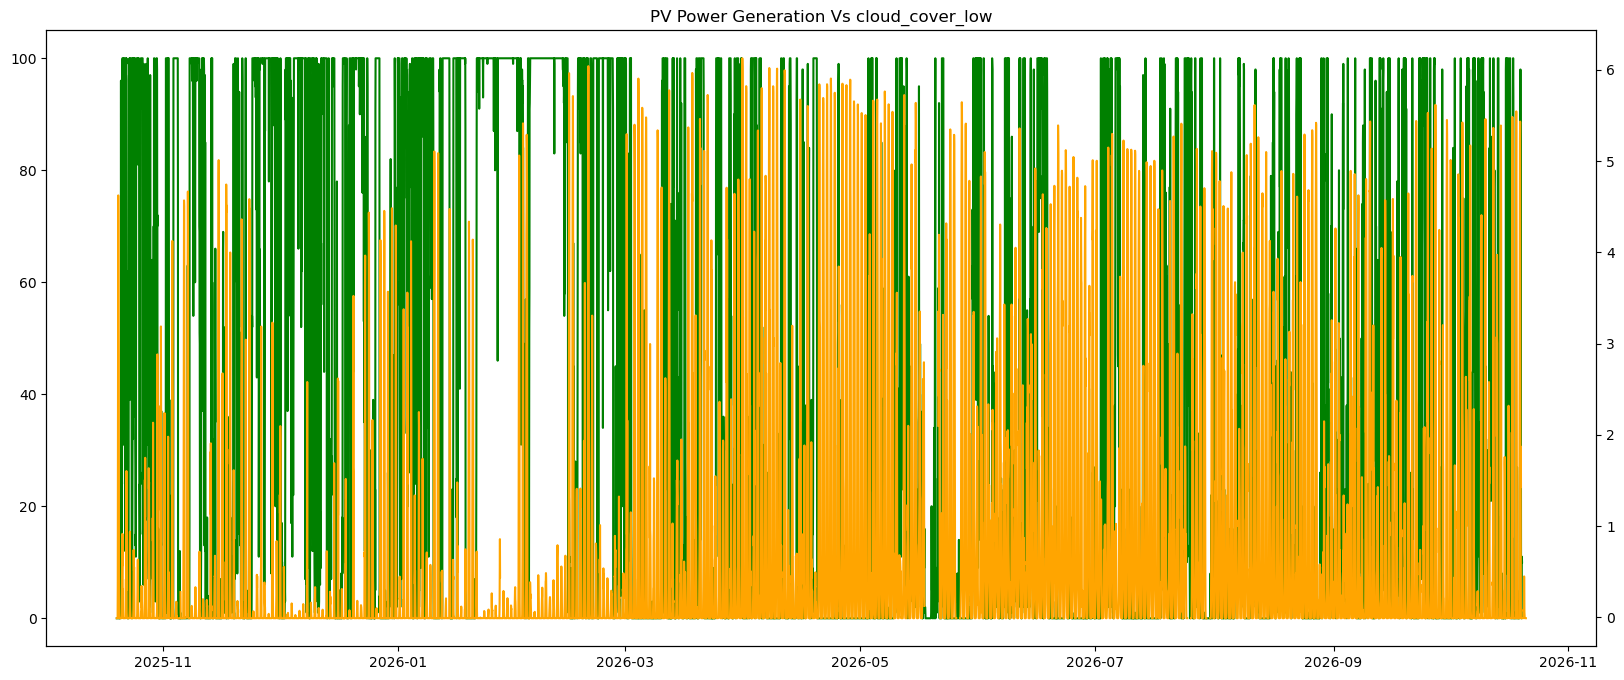

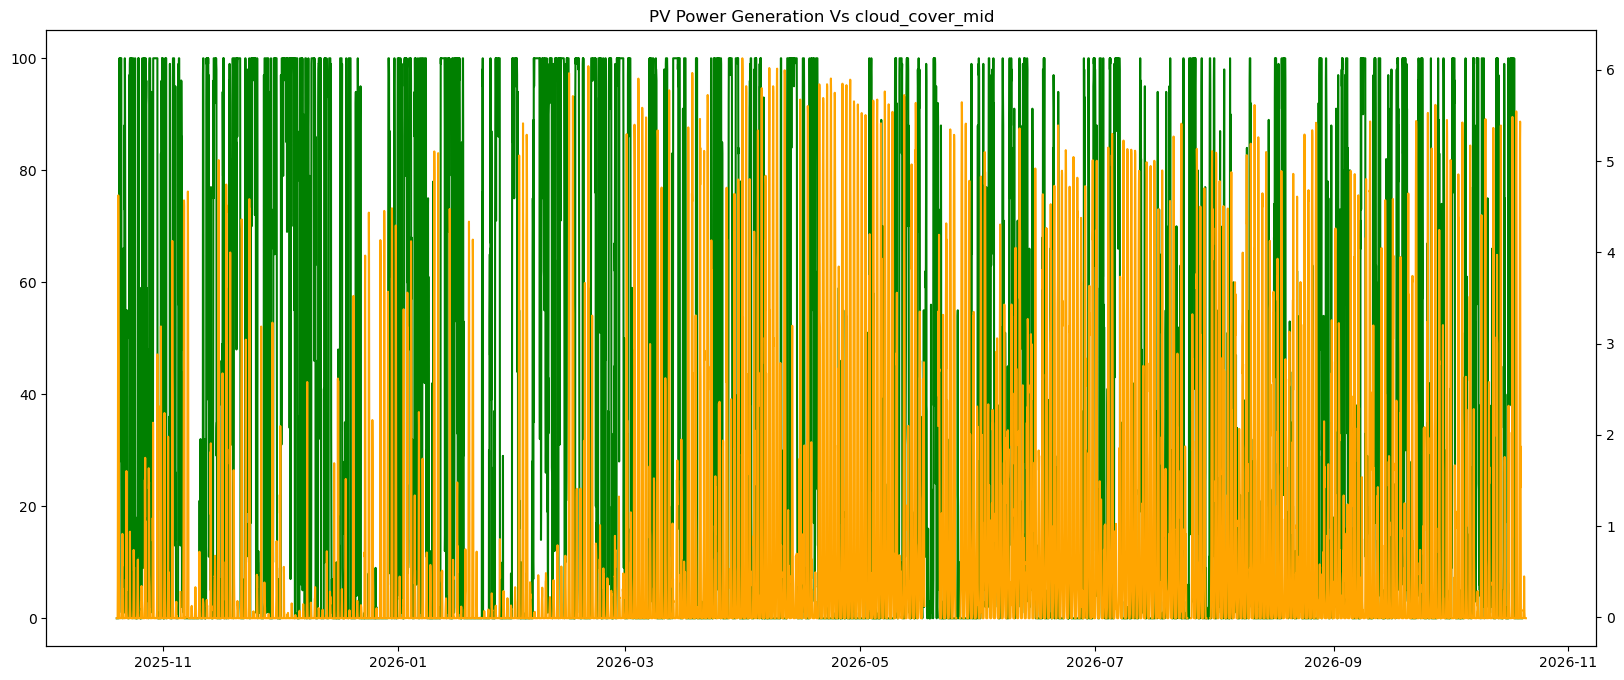

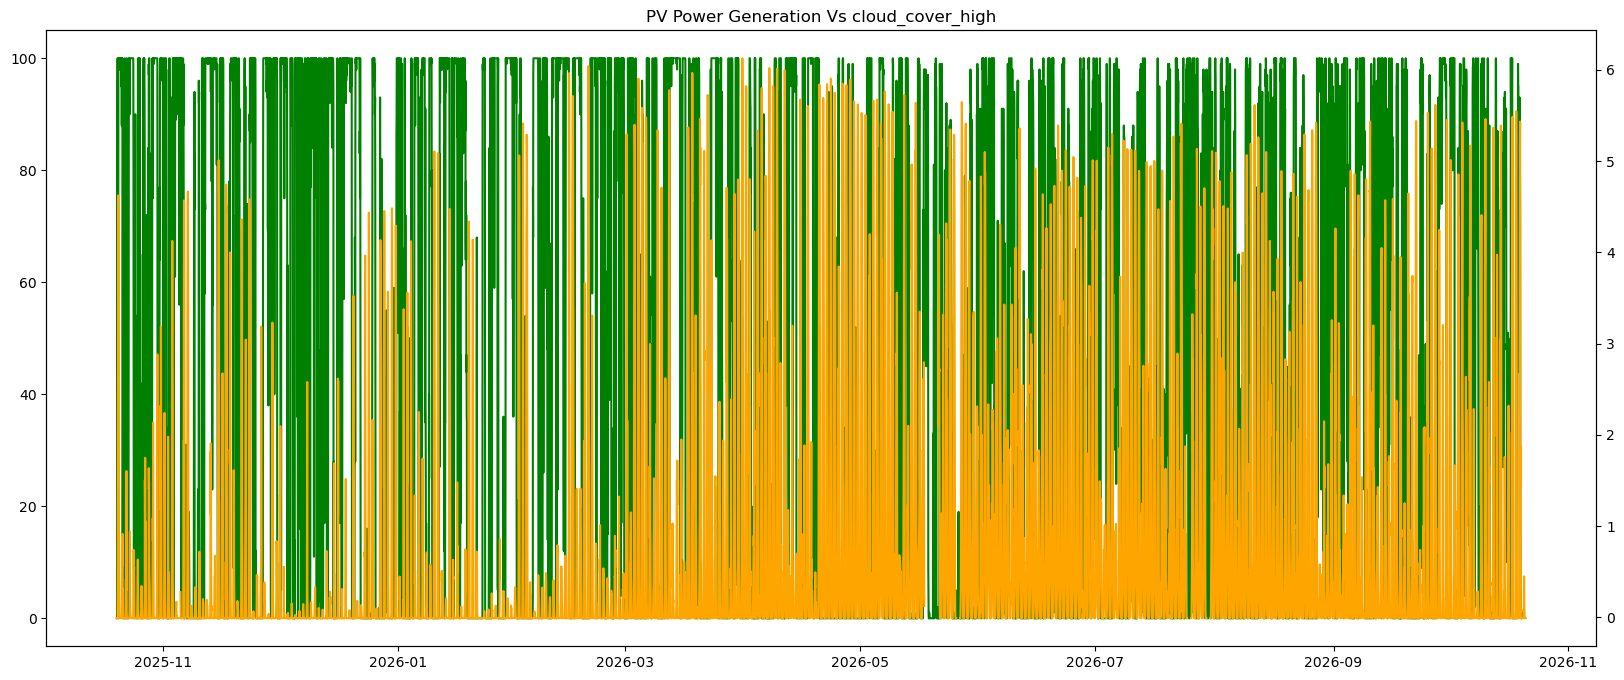

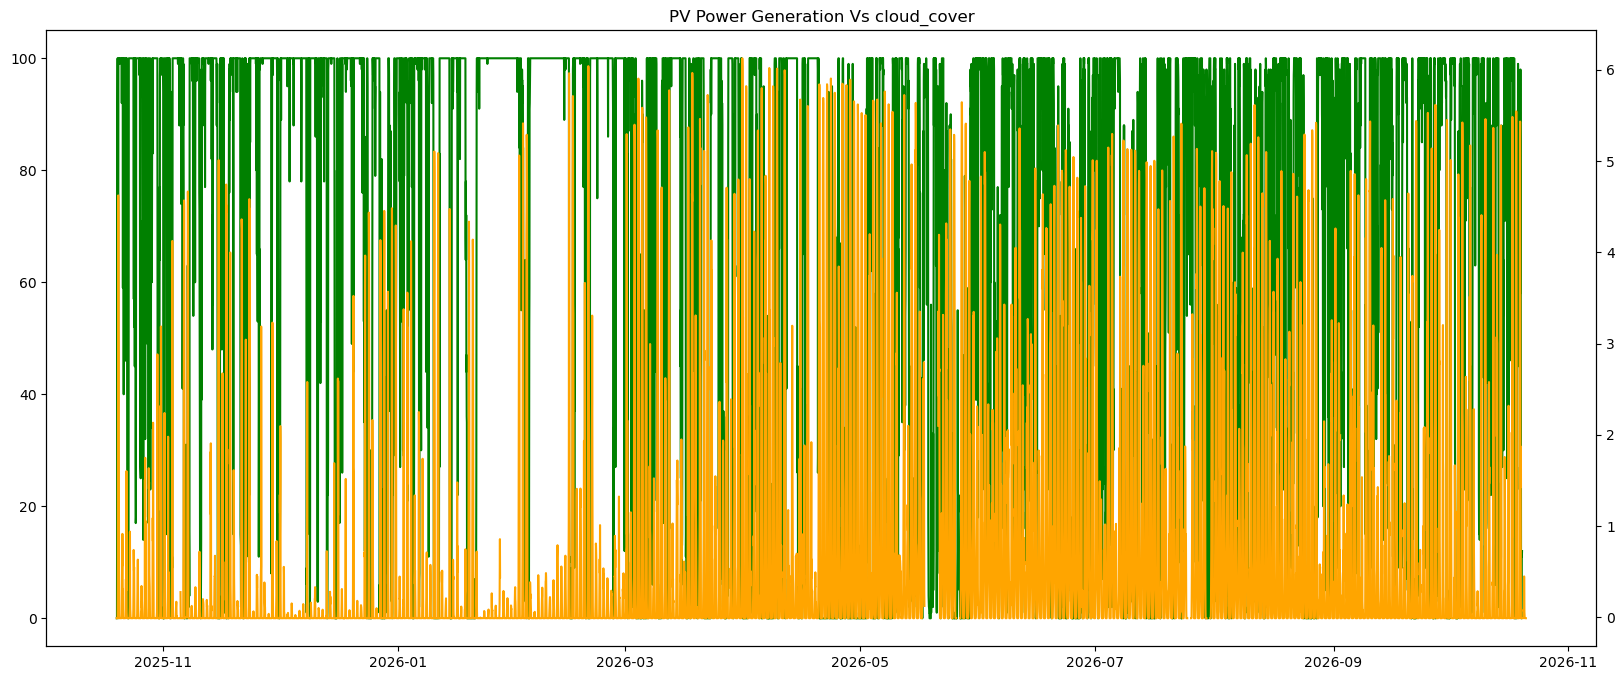

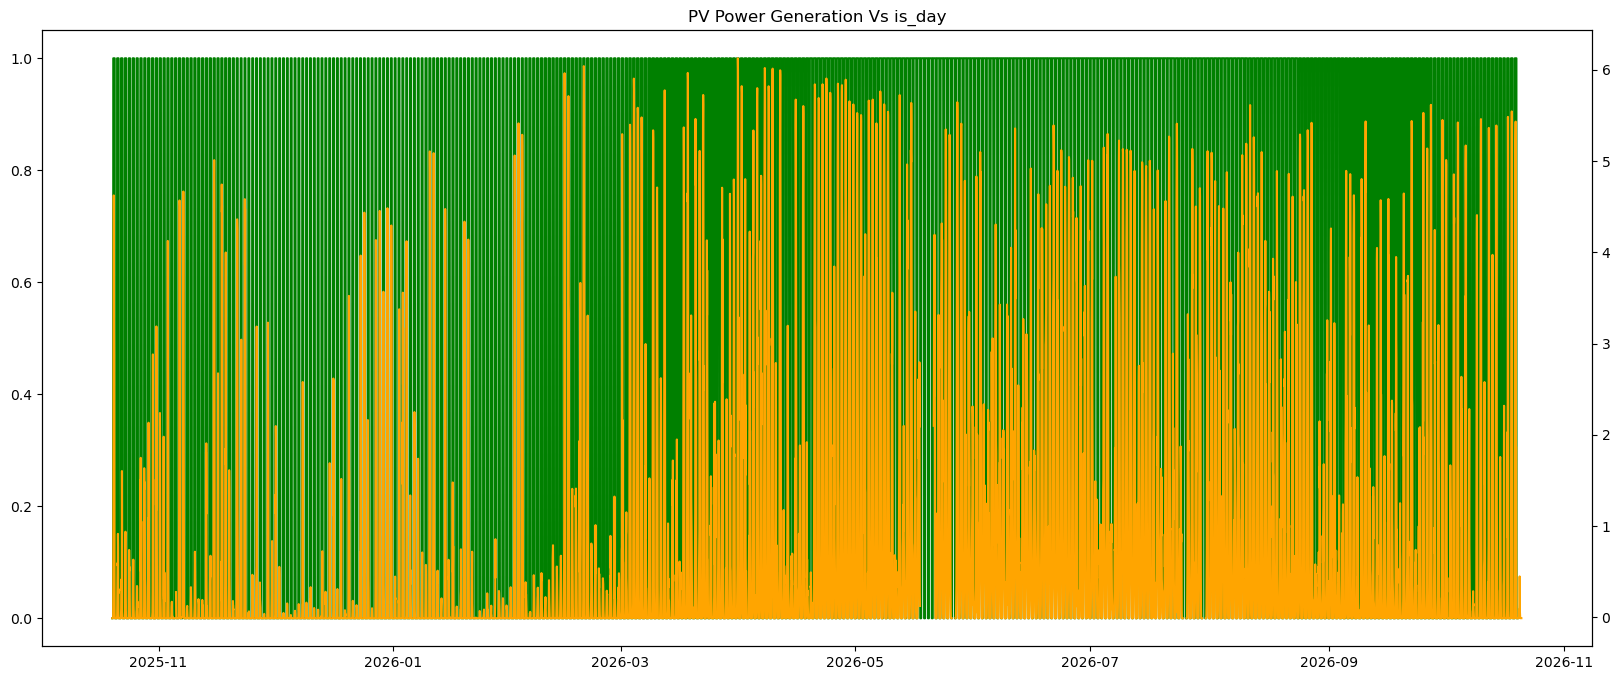

In [6]:
for c in CHANNELS:
    plot_nwp_vs_pv_data(df, c)

In [ ]:
for c in CHANNELS:
    box_plot(df, c)

box_plot(df, 'solar_power')

In [ ]:
for c in CHANNELS:
    scatter_plot(df, c)

In [ ]:
for c in CHANNELS:
    z_score(df, c)

z_score(df, 'solar_power')